# Etapas y el aumento significativo del riesgo de crédito

**Pregunta:** ¿Qué préstamos de una cartera de pequeñas empresas ha pasado el banco de la PCE a 12 meses a la PCE de vida completa, por qué esos y no otros, y cuántos más o menos pasarían si se moviera un parámetro de la regla?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 01 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- comparar la PD que tenía un préstamo en su origen con la PD que tiene a la fecha de reporte sobre la misma ventana, y anualizar ambas para que préstamos de distinta vida restante sean comparables;
- aplicar la regla relativa y absoluta de aumento significativo del riesgo de crédito (SICR) con el respaldo del triple, y decir qué hace cada parámetro de la política con el número de préstamos en la Etapa 2;
- asignar una etapa con las presunciones de 30 y 90 días de mora, la refinanciación, la lista de vigilancia y la exención de bajo riesgo de crédito, y leer qué disparador actuó y por qué tuvo precedencia;
- mantener un préstamo curado en la Etapa 2 durante un período de prueba, y reportar el objetivo de una transferencia colectiva sin sumarlo a la cobertura;
- leer los flujos entre etapas y la cobertura por etapa de una fecha de reporte versionada, y comparar una fecha tranquila con una de estrés.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import dataclasses
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
TRIGGER = {
    "none": "ninguno",
    "relative-absolute": "relativo y absoluto",
    "threefold": "tres veces",
    "dpd-backstop": "respaldo por días de mora",
    "default": "incumplimiento",
    "forbearance": "prórroga",
    "watch-list": "lista de vigilancia",
    "collective": "transferencia colectiva",
    "cure-probation": "período de prueba tras la recuperación",
}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C06 (préstamos 7(a) a pequeñas empresas de la SBA como gemelo público de una cartera hipotecaria; Obras del Gobierno de EE. UU., clase de licencia `mirror-allowed`) en dos fechas de reporte: 2008-12-31, en plena crisis financiera, y 2019-12-31, un año tranquilo. Cada artefacto guarda, además de las estructuras de plazos del cuaderno 01:

- `outputs.settings.sicr`: la política de etapas que usó el flujo de cálculo (el calendario de multiplicadores, el piso absoluto, la razón del triple, los 30 y 90 días);
- `outputs.account_curves`: una muestra de 40 cuentas con su PD acumulada desde el origen y desde la fecha de reporte, trimestre a trimestre durante tres años;
- `outputs.sicr_points`: una muestra de 400 cuentas con su PD anualizada en el origen y ahora, la etapa y el disparador que asignó el flujo de cálculo;
- `outputs.stage_flows` y `outputs.stage_summary`: el movimiento de toda la cartera entre los dos cierres de año y sus totales por etapa.

**Lo que el archivo no tiene:** historia de mora, refinanciación ni lista de vigilancia (hallazgo `F-NO-DELINQUENCY`). En el C06 solo la prueba cuantitativa de SICR puede pasar un préstamo a la Etapa 2, y los días de mora son cero. Los casos de los disparadores cualitativos de abajo son por eso **cuentas construidas**, rotuladas como tales, para mostrar cómo decide el motor.

La celda siguiente carga ambos artefactos, construye la `StagingPolicy` del motor con los ajustes versionados e imprime la política y las versiones del motor.

In [2]:
# Cargar las dos fechas de reporte y construir la política de clasificación desde la configuración versionada
from riskvalidation.provisions import staging, term_structure as tsm

ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived" / "C06"
crisis = json.loads((DERIVED / "rd-2008-12.json").read_text(encoding="utf-8"))
calm = json.loads((DERIVED / "rd-2019-12.json").read_text(encoding="utf-8"))
out = crisis["outputs"]
sicr = out["settings"]["sicr"]
schedule = tuple((row["pd_origination_upper"], row["multiplier"]) for row in sicr["multiplier_schedule"])
policy = staging.StagingPolicy(
    multiplier_schedule=schedule,
    absolute_floor=sicr["absolute_floor"],
    threefold_ratio=sicr["threefold_ratio"],
    dpd_backstop=sicr["dpd_backstop"],
    default_dpd=sicr["default_dpd"],
    probation_months=out["settings"]["probation_months"],
    low_credit_risk_pd=sicr["low_credit_risk_pd"],
)
baked = (crisis["provenance"]["riskvalidation_version"], calm["provenance"]["riskvalidation_version"])
print("motor que calculó los artefactos:", *baked)
print("motor instalado ahora:", md.version("riskvalidation"))
print("tabla de multiplicadores (PD de originación hasta, multiplicador):", policy.multiplier_schedule)
print("piso absoluto:", policy.absolute_floor, "| razón de tres veces:", policy.threefold_ratio)
print("días de mora: presunción e incumplimiento:", policy.dpd_backstop, policy.default_dpd)

motor que calculó los artefactos: 1.0.1 1.0.1
motor instalado ahora: 1.0.1
tabla de multiplicadores (PD de originación hasta, multiplicador): ((0.01, 4.0), (0.05, 2.5), (0.5, 1.5))
piso absoluto: 0.005 | razón de tres veces: 3.0
días de mora: presunción e incumplimiento: 30 90


## Método

La asignación de etapas de IFRS 9 compara el riesgo de crédito de ahora con el riesgo en el reconocimiento inicial (IFRS 9 5.5.3, 5.5.9). La norma no prescribe cómo. Contraste sigue la práctica que encontró su investigación (GPPC 2016, sección 2.7.2; BCBS d350, anexo A26; EBA/Rep/2021/35 y EBA/Rep/2023/36 párrafo 32). Cuatro elementos:

**1. La misma ventana.** La expectativa de origen para la ventana restante es la PD a futuro de la estructura de plazos estimada en el origen, $PD^{\mathrm{orig}}(a, a+H) = \frac{S^{(t_0)}(a) - S^{(t_0)}(a+H)}{S^{(t_0)}(a)}$, y la estimación actual es $PD^{\mathrm{rep}}(0, H)$ de la estructura de plazos a la fecha de reporte. Ambas se anualizan para que préstamos de distinta vida restante sean comparables: $\overline{PD} = 1 - (1 - PD)^{1/H_{\mathrm{años}}}$. La forma geométrica es la convención documentada de Contraste; la EBA dice que compara PD de vida completa anualizadas y, en los pasajes leídos, no enuncia la fórmula (NO VERIFICADO como la de la EBA).

**2. La regla cuantitativa** (relativa y absoluta, con el respaldo del triple), con $m(\cdot)$ un multiplicador que no sube con la PD de origen y $\delta$ un piso absoluto:

$$\mathrm{SICR} = \mathbb{1}\Bigl[\tfrac{\overline{PD}^{\mathrm{rep}}}{\overline{PD}^{\mathrm{orig}}} \ge m(\overline{PD}^{\mathrm{orig}}) \;\wedge\; \overline{PD}^{\mathrm{rep}} - \overline{PD}^{\mathrm{orig}} \ge \delta\Bigr] \;\vee\; \mathbb{1}\Bigl[\tfrac{\overline{PD}^{\mathrm{rep}}}{\overline{PD}^{\mathrm{orig}}} \ge 3\Bigr]$$

**3. La etapa.** Etapa 3 si el préstamo está en incumplimiento (incumplido, o con 90 o más días de mora, B5.5.37); si no, Etapa 2 si actúa algún disparador (más de 30 días de mora como presunción refutable, 5.5.11; refinanciación; lista de vigilancia; una transferencia colectiva; la regla cuantitativa); si no, Etapa 1. La exención de bajo riesgo de crédito (5.5.10) suprime solo los dos disparadores cuantitativos. El motor fija la precedencia de los disparadores y devuelve el que decidió.

**4. El camino de vuelta y la mirada colectiva.** Un préstamo que vuelve a la Etapa 1 se mantiene en la Etapa 2 durante un período de prueba (B5.5.27, un parámetro de política, no un número de la norma). Cuando un impulsor de riesgo se conoce solo por segmento, se mueve a la Etapa 2 una fracción $\pi_g$ del segmento: $\mathrm{monto}_g = \pi_g \sum_{i \in g} \mathrm{VCB}_i$ (B5.5.6).

Los umbrales son la política configurable de Contraste, no regulación: la razón del triple es una expectativa supervisora (EBA/Rep/2023/36 párrafo 32), no IFRS 9.

### Paso 1: la originación frente a la fecha de reporte, en la misma ventana

El artefacto guarda, para 40 cuentas, la PD acumulada de los tres primeros años desde la originación y desde la fecha de reporte. Tomamos una cuenta de Etapa 1 y una de Etapa 2, convertimos cada PD acumulada del mes 36 en una PD anualizada con `annualise_pd` sobre los 3 años, y preguntamos a `sicr_quantitative` si el par es un aumento significativo bajo la política versionada. La figura dibuja las dos curvas de cada cuenta, de modo que la brecha que lee la regla se ve antes de ser una razón.

A0001 | PD anualizada, originación y ahora: 0.002863 0.003408
   razón: 1.19 | diferencia: 0.000545 | aumento significativo: no
A0005 | PD anualizada, originación y ahora: 0.0114 0.030646
   razón: 2.688 | diferencia: 0.019246 | aumento significativo: sí


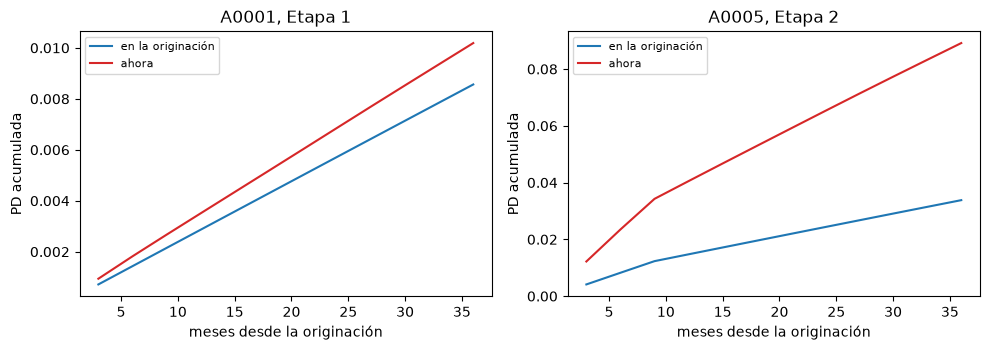

In [3]:
# Anualizar la PD de una cuenta de Etapa 1 y una de Etapa 2, probarlas y dibujar sus curvas
curves = {c["account_id"]: c for c in out["account_curves"]}
picked = [next(a for a, c in curves.items() if c["stage"] == s) for s in ("stage1", "stage2")]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for ax, account_id in zip(axes, picked):
    c = curves[account_id]
    ann_orig = float(tsm.annualise_pd(np.array([c["origination_cumulative_pd"][-1]]), 3.0)[0])
    ann_now = float(tsm.annualise_pd(np.array([c["current_cumulative_pd"][-1]]), 3.0)[0])
    flagged = bool(staging.sicr_quantitative(np.array([ann_orig]), np.array([ann_now]), policy)[0])
    print(account_id, "| PD anualizada, originación y ahora:", round(ann_orig, 6), round(ann_now, 6))
    print("   razón:", round(ann_now / ann_orig, 3), "| diferencia:", round(ann_now - ann_orig, 6),
          "| aumento significativo:", "sí" if flagged else "no")
    ax.plot(c["months"], c["origination_cumulative_pd"], color="tab:blue", label="en la originación")
    ax.plot(c["months"], c["current_cumulative_pd"], color="tab:red", label="ahora")
    ax.set_xlabel("meses desde la originación")
    ax.set_ylabel("PD acumulada")
    ax.set_title(f"{account_id}, Etapa {c['stage'][-1]}")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La cuenta A0001 está en la Etapa 1: su curva actual queda apenas por encima de su curva en la originación, y la PD anualizada pasó de 0,0029 a 0,0034, una razón de 1,19, lejos de cualquier multiplicador de la tabla. La cuenta A0005 es lo contrario: su PD acumulada a 36 meses creció de 3,4% a 8,9%, una razón anualizada de 2,69 y una diferencia de 0,0192. Su PD de originación cae en la banda cuyo multiplicador es 2,5, de modo que se cumplen la razón y el piso absoluto y el motor la marca.

### Paso 2: la regla sobre 400 cuentas

`sicr_points` guarda las PD anualizadas de 400 cuentas en la originación y ahora. Las pasamos a `allocate_stages` con cero días de mora y sin marca cualitativa, porque el archivo no tiene ninguna, y dejamos que el motor asigne la etapa y nombre el disparador que decidió. La figura ubica cada cuenta por sus dos PD en ejes logarítmicos. La línea punteada es PD igual y la discontinua es tres veces la PD de originación; la regla solo puede actuar por encima del multiplicador de la banda de la cuenta.

disparador: ninguno | cuentas: 384
disparador: relativo y absoluto | cuentas: 16
cuentas: 400 | proporción en la Etapa 2: 0.04
mayor razón de la muestra: 2.764


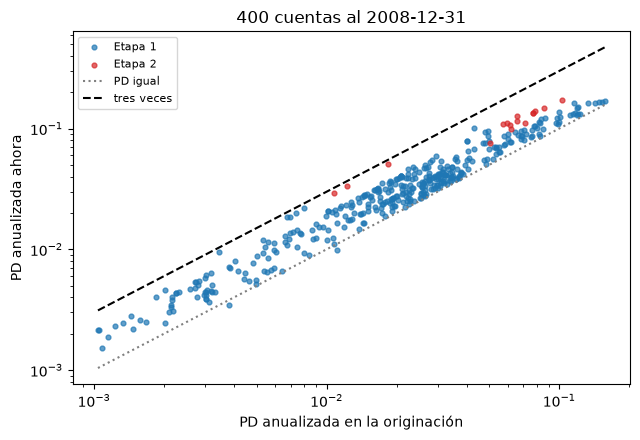

In [4]:
# Asignar las etapas de las 400 cuentas muestreadas con el motor, contar los disparadores y dibujar las cuentas
points = out["sicr_points"]
orig = np.array([p["pd_origination_annualised"] for p in points])
now = np.array([p["pd_current_annualised"] for p in points])
no_flag = np.zeros(len(points), dtype=bool)
no_dpd = np.zeros(len(points), dtype=np.int64)
result = staging.allocate_stages(orig, now, no_dpd, no_flag, no_flag, no_flag, policy)
for trigger in sorted({str(t) for t in result.trigger}):
    print("disparador:", TRIGGER[trigger], "| cuentas:", int(np.sum(result.trigger == trigger)))
print("cuentas:", len(points), "| proporción en la Etapa 2:", round(float(np.mean(result.stage == 2)), 4))
print("mayor razón de la muestra:", round(float((now / orig).max()), 3))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for stage_no, color in ((1, "tab:blue"), (2, "tab:red")):
    mask = result.stage == stage_no
    ax.scatter(orig[mask], now[mask], s=12, color=color, alpha=0.7, label=f"Etapa {stage_no}")
grid = np.array([orig.min(), orig.max()])
ax.plot(grid, grid, color="grey", linestyle=":", label="PD igual")
ax.plot(grid, 3.0 * grid, color="black", linestyle="--", label="tres veces")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("PD anualizada en la originación")
ax.set_ylabel("PD anualizada ahora")
ax.set_title("400 cuentas al 2008-12-31")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Dieciséis de las 400 cuentas, 4% de la muestra, quedan en la Etapa 2 y todas por la regla relativa y absoluta. Son los puntos rojos que se elevan muy por encima de la línea de PD igual. Ninguna cuenta llega a tres veces su PD de originación: la mayor razón de la muestra es 2,76, de modo que el respaldo de tres veces, que atraparía un préstamo cuyo riesgo se triplicó sea cual sea su banda, nunca actúa sobre esta muestra.

### Paso 3: qué hace cada parámetro de la política

Un validador pregunta cuántos préstamos se mueven cuando se mueve un parámetro. La celda repite `sicr_quantitative` sobre las mismas 400 cuentas con el piso absoluto $\delta$ en 0, 0,005 (el valor versionado), 0,01 y 0,02, con la razón de tres veces en 2, 3 y 5, y con toda la tabla de multiplicadores escalada por 0,75, 1 y 1,25. La política es una dataclass inmutable, así que `dataclasses.replace` crea una nueva y deja intacta la versionada. Cada parámetro tiene un panel con el número de préstamos marcados.

política versionada: marcados de 400 : 16
piso absoluto: (0.0, 0.005, 0.01, 0.02) -> [16, 16, 16, 15]
razón de tres veces: (2.0, 3.0, 5.0) -> [35, 16, 16]
escala de los multiplicadores: (0.75, 1.0, 1.25) -> [109, 16, 2]


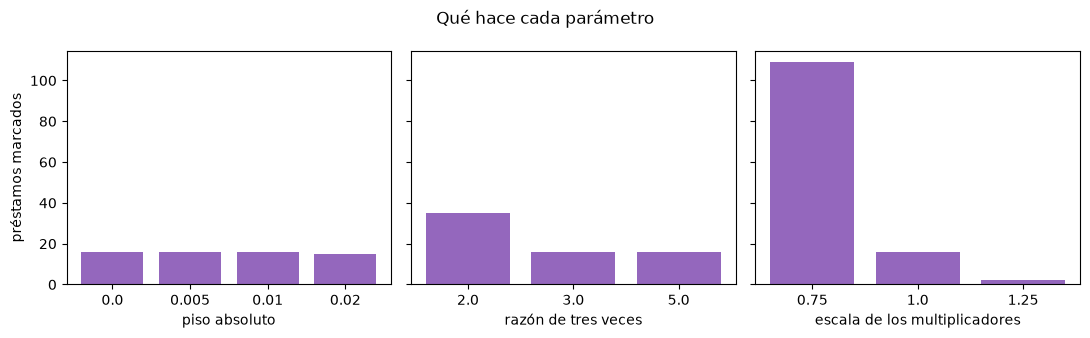

In [5]:
# Contar los préstamos marcados mientras se mueve un parámetro y los demás quedan como versionados
floors, ratios, scales = (0.0, 0.005, 0.01, 0.02), (2.0, 3.0, 5.0), (0.75, 1.0, 1.25)
flagged = staging.sicr_quantitative(orig, now, policy)
by_floor, by_ratio, by_scale = [], [], []
for floor in floors:
    by_floor.append(int(staging.sicr_quantitative(orig, now, dataclasses.replace(policy, absolute_floor=floor)).sum()))
for ratio in ratios:
    by_ratio.append(int(staging.sicr_quantitative(orig, now, dataclasses.replace(policy, threefold_ratio=ratio)).sum()))
for scale in scales:
    scaled = tuple((upper, mult * scale) for upper, mult in policy.multiplier_schedule)
    new_policy = dataclasses.replace(policy, multiplier_schedule=scaled)
    by_scale.append(int(staging.sicr_quantitative(orig, now, new_policy).sum()))
print("política versionada: marcados de", len(points), ":", int(flagged.sum()))
print("piso absoluto:", floors, "->", by_floor)
print("razón de tres veces:", ratios, "->", by_ratio)
print("escala de los multiplicadores:", scales, "->", by_scale)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, grid_values, counts, label in ((axes[0], floors, by_floor, "piso absoluto"),
                                       (axes[1], ratios, by_ratio, "razón de tres veces"),
                                       (axes[2], scales, by_scale, "escala de los multiplicadores")):
    ax.bar([str(v) for v in grid_values], counts, color="tab:purple")
    ax.set_xlabel(label)
axes[0].set_ylabel("préstamos marcados")
fig.suptitle("Qué hace cada parámetro")
fig.tight_layout()
plt.show()

Los tres paneles no son iguales. El piso absoluto casi no importa: la cuenta es 16 para un piso de 0, 0,005 y 0,01 y 15 para 0,02. La razón de tres veces solo cambia la cuenta cuando se baja a 2, lo que marca 35 préstamos. La tabla de multiplicadores es la palanca: escalarla por 0,75 marca 109 préstamos y por 1,25 solo 2. Esta es la cantidad que un validador debe cuestionar, junto con cómo se calibró a la PD de originación, porque la política decide cuántos préstamos llevan una PCE de vida completa.

### Paso 4: las presunciones y la precedencia en cuentas construidas

El archivo no tiene historial de morosidad (hallazgo `F-NO-DELINQUENCY`), así que los disparadores cualitativos no se pueden leer de él. La celda siguiente construye siete cuentas **construidas**, una por regla, y da a cada una el mismo par tranquilo de PD salvo la última, que tiene una PD triplicada. Luego deja que `allocate_stages` decida. Lo que importa es el orden: una cuenta en incumplimiento es Etapa 3 pase lo que pase, 31 días de mora es Etapa 2 aun con PD tranquilas, la prórroga y la lista de vigilancia son Etapa 2, y cuando valen dos razones se informa la de mayor precedencia.

In [6]:
# Siete cuentas construidas, una regla cada una, y la etapa y el disparador que el motor asigna
labels = [
    "tranquila", "30 días de mora", "31 días de mora", "90 días de mora",
    "con prórroga", "lista de vigilancia y 31 días", "PD triplicada",
]
pd_orig = np.full(7, 0.02)
pd_now = np.array([0.021, 0.021, 0.021, 0.021, 0.021, 0.021, 0.061])
dpd = np.array([0, 30, 31, 90, 0, 31, 0])
forborne = np.array([False, False, False, False, True, False, False])
watch = np.array([False, False, False, False, False, True, False])
defaulted = np.zeros(7, dtype=bool)
built = staging.allocate_stages(pd_orig, pd_now, dpd, forborne, watch, defaulted, policy)
for label, stage, trigger in zip(labels, built.stage, built.trigger):
    print(f"{label:30s} -> Etapa {int(stage)} | disparador: {TRIGGER[str(trigger)]}")

tranquila                      -> Etapa 1 | disparador: ninguno
30 días de mora                -> Etapa 1 | disparador: ninguno
31 días de mora                -> Etapa 2 | disparador: respaldo por días de mora
90 días de mora                -> Etapa 3 | disparador: incumplimiento
con prórroga                   -> Etapa 2 | disparador: prórroga
lista de vigilancia y 31 días  -> Etapa 2 | disparador: respaldo por días de mora
PD triplicada                  -> Etapa 2 | disparador: relativo y absoluto


Treinta días de mora se queda en la Etapa 1 y 31 pasa a la Etapa 2, de modo que la presunción es exacta en su frontera; 90 días es Etapa 3. La prórroga sola es Etapa 2. La cuenta en la lista de vigilancia con 31 días se informa con el disparador de días de mora y no con la lista de vigilancia, porque la regla de días de mora va primero en la precedencia. Estos casos son construidos para mostrar las decisiones del motor y no son hallazgos sobre la cartera, que no tiene ninguno.

### Paso 5: la exención por bajo riesgo de crédito

La exención de 5.5.10 permite a una institución mantener en la Etapa 1 un préstamo cuyo riesgo de crédito es bajo en la fecha de reporte, aunque haya subido. Es un parámetro de política, `low_credit_risk_pd`, y suprime solo los dos disparadores cuantitativos, nunca los días de mora ni la prórroga (5.5.11, B5.5.37). La celda agrega una octava cuenta cuya PD subió de 0,002 a 0,0082 y repite las mismas cuentas con un corte de 0,03, para ver qué decisiones cambian.

In [7]:
# Agregar una octava cuenta y repetir con un corte de bajo riesgo de crédito de 0.03
exempt_policy = dataclasses.replace(policy, low_credit_risk_pd=0.03)
orig8 = np.append(pd_orig, 0.002)
now8 = np.append(pd_now, 0.0082)
flags = (np.append(dpd, 0), np.append(forborne, False), np.append(watch, False), np.append(defaulted, False))
without = staging.allocate_stages(orig8, now8, *flags, policy)
with_exemption = staging.allocate_stages(orig8, now8, *flags, exempt_policy)
for k in (6, 7):
    print("cuenta", k + 1, "| sin la exención:", int(without.stage[k]), TRIGGER[str(without.trigger[k])])
    print("   | con ella:", int(with_exemption.stage[k]), TRIGGER[str(with_exemption.trigger[k])])
print("cambios entre las seis primeras cuentas:", int(np.sum(with_exemption.stage[:6] != without.stage[:6])))

cuenta 7 | sin la exención: 2 relativo y absoluto
   | con ella: 2 relativo y absoluto
cuenta 8 | sin la exención: 2 relativo y absoluto
   | con ella: 1 ninguno
cambios entre las seis primeras cuentas: 0


La cuenta 8, cuya PD subió de 0,002 a 0,0082 y queda bajo el corte, es Etapa 2 sin la exención y Etapa 1 con ella. La cuenta 7, la triplicada, está sobre el corte con 0,061 y sigue en la Etapa 2. Ninguna de las seis primeras cuentas cambia, de modo que la exención dejó intactos todos los casos de días de mora y de prórroga. La exención es una decisión de política con un costo, porque deja fuera de la medición de vida completa préstamos de PD baja que parecen riesgosos, y un validador lee su corte con el mismo cuidado que los multiplicadores.

### Paso 6: el camino de vuelta y la transferencia colectiva

`apply_cure_probation` mantiene en la Etapa 2 una cuenta que ahora es Etapa 1, era Etapa 2 antes y se recuperó hace menos de `probation_months`. La política versionada de C06 no tiene período de prueba, porque el archivo no tiene fechas de recuperación y las fechas de reporte distan un año, así que la celda usa un período de prueba de 12 meses sobre tres cuentas construidas que se recuperaron hace 3, 12 y 20 meses. `collective_transfer` informa, para cada segmento, el monto que una regla colectiva pasaría a la Etapa 2, y no agrega nada a la reserva.

In [8]:
# Mantener en Etapa 2 las cuentas recuperadas durante un período de prueba e informar una meta colectiva
probation_policy = dataclasses.replace(policy, probation_months=12)
quiet = np.zeros(3, dtype=bool)
now_result = staging.allocate_stages(np.full(3, 0.02), np.full(3, 0.021), np.zeros(3, dtype=np.int64),
                                     quiet, quiet, quiet, probation_policy)
months_since_cure = np.array([3, 12, 20])
held = staging.apply_cure_probation(np.array([1, 1, 1]), np.array([2, 2, 2]), months_since_cure,
                                    probation_policy, now_result)
for months_ago, stage, trigger in zip(months_since_cure, held.stage, held.trigger):
    print("meses desde la recuperación:", int(months_ago), "-> Etapa", int(stage), "|", TRIGGER[str(trigger)])

gross = np.array([1_000_000.0, 3_000_000.0, 2_000_000.0, 4_000_000.0])
segments = np.array(["A", "B", "B", "A"])
target = staging.collective_transfer(gross, segments, {"A": 0.10, "B": 0.25})
for segment, amount in target.items():
    print("meta colectiva del segmento", segment, ":", amount)

meses desde la recuperación: 3 -> Etapa 2 | período de prueba tras la recuperación
meses desde la recuperación: 12 -> Etapa 1 | ninguno
meses desde la recuperación: 20 -> Etapa 1 | ninguno
meta colectiva del segmento A : 500000.0
meta colectiva del segmento B : 1250000.0


Solo la cuenta que se recuperó hace tres meses sigue en la Etapa 2, con el disparador de período de prueba; las cuentas recuperadas hace 12 y 20 meses cumplieron el período y vuelven a la Etapa 1. La meta colectiva es un monto por segmento: 10% del importe en libros bruto del segmento A y 25% del segmento B. Es un número que hay que convertir en cuentas con una regla que el banco declara, y nunca un monto que se sume a la reserva, y por eso el motor lo devuelve aparte.

### Paso 7: los flujos de etapas y la cobertura por etapa, en una crisis y en un año calmo

El artefacto versionado informa el movimiento de toda la cartera entre las dos fechas de cierre de año, en cuentas y en importe en libros bruto, y la reserva y la cobertura por etapa al final. Esto es lo que necesita una revelación IFRS 7. La celda lee los flujos de 2008, calcula la proporción de las cuentas de Etapa 1 al inicio que pasaron a la Etapa 2 en el año, e imprime el resumen por etapa de ambas fechas. La figura dibuja adónde fueron las cuentas de Etapa 1 al inicio y la cobertura (reserva sobre importe en libros bruto) por etapa.

cuentas de Etapa 1 al inicio: 325731 | pasaron a la Etapa 2: 12407
proporción: 0.0381
2008-12-31 | cuentas por etapa: [297977, 13526, 0]
   cobertura: [0.0171, 0.1297, 0.0]
2019-12-31 | cuentas por etapa: [271801, 0, 0]
   cobertura: [0.0058, 0.0, 0.0]
cobertura de la Etapa 2 sobre la Etapa 1, 2008: 7.594


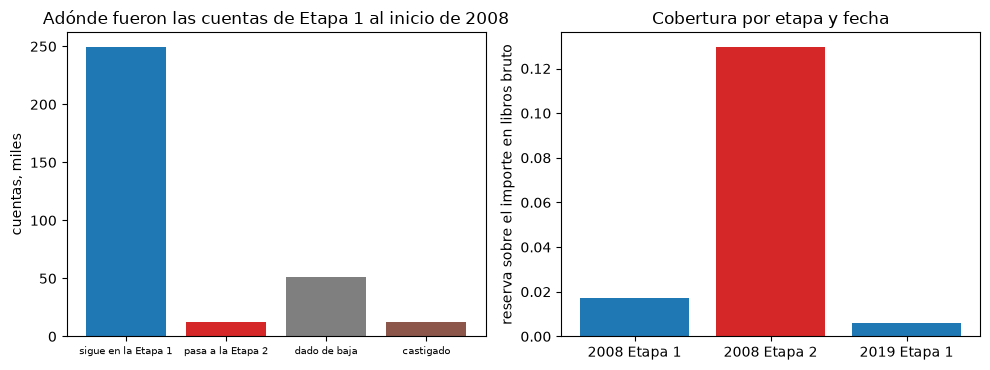

In [9]:
# Leer los flujos de etapas del año de crisis y el resumen por etapa de ambas fechas, y dibujarlos
flows = out["stage_flows"]["flows"]
from_stage1 = {f["target"]: f["accounts"] for f in flows if f["source"] == "stage1"}
opening = sum(from_stage1.values())
print("cuentas de Etapa 1 al inicio:", opening, "| pasaron a la Etapa 2:", from_stage1["stage2"])
print("proporción:", round(from_stage1["stage2"] / opening, 4))
coverage = {}
for name, art in (("2008-12-31", crisis), ("2019-12-31", calm)):
    rows = {r["stage"]: r for r in art["outputs"]["stage_summary"]["rows"]}
    coverage[name] = [rows[s]["coverage"] for s in ("stage1", "stage2")]
    print(name, "| cuentas por etapa:", [rows[s]["accounts"] for s in ("stage1", "stage2", "stage3")])
    print("   cobertura:", [round(rows[s]["coverage"], 4) for s in ("stage1", "stage2", "stage3")])
ratio_2008 = coverage["2008-12-31"][1] / coverage["2008-12-31"][0]
print("cobertura de la Etapa 2 sobre la Etapa 1, 2008:", round(ratio_2008, 3))

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
targets = ["stage1", "stage2", "derecognised", "written-off"]
names = ["sigue en la Etapa 1", "pasa a la Etapa 2", "dado de baja", "castigado"]
colors = ["tab:blue", "tab:red", "tab:grey", "tab:brown"]
left.bar(names, [from_stage1[t] / 1000 for t in targets], color=colors)
left.set_ylabel("cuentas, miles")
left.set_title("Adónde fueron las cuentas de Etapa 1 al inicio de 2008")
left.tick_params(axis="x", labelsize=7)
right.bar(["2008 Etapa 1", "2008 Etapa 2", "2019 Etapa 1"],
          [coverage["2008-12-31"][0], coverage["2008-12-31"][1], coverage["2019-12-31"][0]],
          color=["tab:blue", "tab:red", "tab:blue"])
right.set_ylabel("reserva sobre el importe en libros bruto")
right.set_title("Cobertura por etapa y fecha")
fig.tight_layout()
plt.show()

En el año de crisis, 12.407 de las 325.731 cuentas que empezaron en la Etapa 1 pasaron a la Etapa 2, 3,81%, y un número mayor salió de la cartera por prepago o castigo. La cobertura de la Etapa 2 fue 12,97% frente a 1,71% de la Etapa 1, 7,59 veces mayor, que es el acantilado del cuaderno 01 visto en la cartera. Al 2019-12-31 ningún préstamo estaba en la Etapa 2 y la cobertura de la Etapa 1 era 0,58%, una fecha calma en que la clasificación no tiene nada que mover.

## Resultados

**Respuesta:** Bajo la política versionada 16 de los 400 préstamos muestreados, 0,04 de la muestra, pasan de la medición de la Etapa 1 a la PCE de vida completa de la Etapa 2, todos por la regla relativa y absoluta porque su PD anualizada subió al menos el multiplicador de su banda; la tabla de multiplicadores decide cuántos, ya que escalarla por 0,75 marca 109 préstamos y por 1,25 marca 2, mientras que el piso absoluto (16 préstamos, o 15 con un piso de 0,02) y la razón de tres veces (35 préstamos, solo cuando se baja a 2) casi no importan.

- **Dos cuentas, una regla.** La cuenta A0001 de Etapa 1 tiene una PD anualizada de 0,0029 en la originación y 0,0034 ahora, una razón de 1,19: sin aumento significativo. La cuenta A0005 de Etapa 2 va de 0,0114 a 0,0306, una razón de 2,69 y una diferencia de 0,0192: su PD de originación cae en la banda cuyo multiplicador es 2,5, de modo que se cumplen la razón y el piso.
- **El respaldo de tres veces nunca actúa aquí.** La mayor razón de la muestra es 2,76, así que ninguna cuenta está a tres veces su PD de originación, y la razón de tres veces cambia la cuenta solo cuando se baja a 2.
- **La tabla de multiplicadores es la palanca.** Es la cantidad que un validador debe cuestionar, junto con su calibración a la PD de originación, y el umbral no debe aflojarse cuando las condiciones empeoran (EBA/Rep/2023/36 párrafo 33).
- **Las reglas cualitativas son exactas en sus fronteras.** 30 días de mora es Etapa 1 y 31 es Etapa 2 por el respaldo; 90 es Etapa 3; la prórroga es Etapa 2; cuando valen dos razones, se informa el disparador de mayor precedencia. La exención por bajo riesgo de crédito suprimió el disparador relativo y absoluto de la cuenta cuya PD subió de 0,002 a 0,0082 y dejó intactos todos los casos de días de mora y de prórroga.
- **Período de prueba y vista colectiva.** Con un período de prueba de 12 meses, solo la cuenta recuperada hace 3 meses sigue en la Etapa 2, con el disparador de período de prueba. Las metas colectivas son montos por convertir en cuentas, nunca por sumar a la reserva.
- **Un año de crisis y un año calmo.** En 2008, 12.407 de las 325.731 cuentas de Etapa 1 al inicio (3,81%) pasaron a la Etapa 2, y la cobertura de la Etapa 2 fue 12,97% frente a 1,71% de la Etapa 1, 7,59 veces mayor. Al 2019-12-31 ningún préstamo estaba en la Etapa 2 y la cobertura de la Etapa 1 era 0,58%.

Lo que este cuaderno no muestra: el flujo de cálculo clasifica los préstamos solo con la regla cuantitativa, porque el archivo no tiene historial de morosidad (hallazgo `F-NO-DELINQUENCY`), de modo que la Etapa 3 no tiene saldo a una fecha y los casos de días de mora son construidos. Las 400 cuentas son una muestra, mientras que los flujos y resúmenes de etapas son los de toda la cartera. Si la clasificación predice los incumplimientos es una pregunta de validación, que responde el cuaderno 05.

## Resumen

- La clasificación en etapas compara la PD de ahora con la PD de la originación en la misma ventana, ambas anualizadas, y el motor aplica una regla relativa y absoluta con un respaldo de tres veces; los parámetros son política, no regulación.
- `allocate_stages` devuelve la etapa y el disparador que decidió, con una precedencia fija: incumplimiento, días de mora, prórroga, lista de vigilancia, colectivo, relativo y absoluto, tres veces. La exención por bajo riesgo de crédito toca solo los dos disparadores cuantitativos.
- En C06 a la fecha de crisis hay 16 de 400 cuentas muestreadas en la Etapa 2, y la tabla de multiplicadores, no el piso ni la razón de tres veces, decide cuántas.
- El período de prueba y la transferencia colectiva son funciones separadas: la primera mantiene en la Etapa 2 a un préstamo recuperado, la segunda solo informa un monto meta.
- Los flujos de etapas y la cobertura por etapa son lo que necesita una tabla IFRS 7: la cobertura de la Etapa 2 fue 7,59 veces la de la Etapa 1 en 2008, y no hubo Etapa 2 en 2019.

**Qué probar después.** Cambia `probation_months` a 6 y a 24, escala la tabla de multiplicadores por 0,5 (el motor la rechazará: los multiplicadores deben ser al menos 1) y lee el mensaje. Luego sigue con el cuaderno 03, que pondera los escenarios detrás de estas PD.

## Referencias

- IASB, IFRS 9 Instrumentos financieros (julio de 2014), tal como lo adopta el Reglamento (UE) 2016/2067 de la Comisión, párrafos 5.5 y B5.5, y las enmiendas a la IFRS 7, 35A a 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 de junio de 2016, secciones 2.1.1, 2.7.2 y 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), párrafos 36, 50 y 51 y párrafo A26 del anexo. https://www.bis.org/bcbs/publ/d350.htm
- EBA (2021), IFRS 9 implementation by EU institutions, informe de seguimiento, EBA/Rep/2021/35. https://www.eba.europa.eu/sites/default/files/document_library/Publications/Reports/2021/1024609/IFRS9%20monitoring%20report.pdf
- EBA (2023), IFRS 9 implementation by EU institutions, informe de seguimiento 2023, EBA/Rep/2023/36, párrafos 29 a 33 y 94 a 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf
- Botha, A. y Verster, T. (2025), Approaches for modelling the term-structure of default risk under IFRS 9: a tutorial using discrete-time survival analysis, ecuaciones 6 a 10. https://arxiv.org/abs/2507.15441